# 06 — Midterm results: position and format bias on 100 Arena pairs
The proposal's full design on the 100 frozen pilot pairs (from the format pool, so both answers use markdown),
Qwen3 **0.6B and 1.7B** (BF16) plus **4B and 8B as 8-bit quantized models ("-q8")**, thinking **off and on**,
10 judge calls per pair:
original/plain × original/plain in both orders, plus the original pair repeated in both orders (noise floor).
Run locally (MLX, same pinned checkpoints) with `scripts/run_midterm.py`. Measures follow
`docs/evaluation_contract.md` §5. **Precision per size: 0.6B/1.7B BF16; "4B-q8" = 8-bit MLX; "8B-awq" = Qwen's official 4-bit AWQ on vLLM
(contract specifies BF16). Size comparisons therefore mix precision — a stated confound.
Scope: 100 of 1,000 pairs — an interim result, not a test of H1–H3 as pre-registered.**

In [1]:
# --- Setup: runs in Google Colab (Drive = persistent storage) or locally ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Put this repository at MyDrive/dsc261 (this part runs from chatbot_arena/; outputs persist there).
    os.environ["DSC261_ROOT"] = "/content/drive/MyDrive/dsc261/chatbot_arena"
    get_ipython().run_line_magic("pip", "install -q datasets huggingface_hub pyarrow transformers openai scikit-learn statsmodels nbformat")
    try:
        from google.colab import userdata
        for k in ("HF_TOKEN", "FEATHERLESS_API_KEY", "OPENROUTER_API_KEY", "TOGETHER_API_KEY"):
            try:
                os.environ.setdefault(k, userdata.get(k) or "")
            except Exception:
                pass
    except Exception:
        pass
else:
    os.environ.setdefault("DSC261_ROOT", os.path.abspath(".."))
ROOT = os.environ["DSC261_ROOT"]
sys.path.insert(0, os.path.join(ROOT, "src"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
from dsc261 import common as C
print("project root:", ROOT, "| seed:", C.SEED, "| pipeline:", C.PIPELINE_VERSION)


project root: /Users/257s/dev/dsc261 | seed: 261 | pipeline: week1-v1.0


In [2]:
from dsc261 import analysis as AN, evaldata as E
import glob
logs = [C.path("api", "pilot_local", "pilot_log.jsonl")] + sorted(glob.glob(C.path("api", "midterm_remote", "*.jsonl")))
v = pd.concat([AN.load_verdicts(f) for f in logs], ignore_index=True).drop_duplicates("request_id", keep="last")
print("logs read:", [os.path.relpath(f, ROOT) for f in logs])
pairs = pd.read_parquet(C.path("data", "processed", "pilot_pairs.parquet"))
v = v[v.pair_id.isin(pairs.pair_id)]
ORDER = ["0.6B", "1.7B", "4B", "4B-q8", "8B", "8B-q8", "8B-awq"]
CONFIGS = [f"{s}-{m}" for s in ORDER for m in ("nothink", "think")
           if (v.config == f"{s}-{m}").sum() >= 10 * len(pairs) * 0.9]  # configs that are (nearly) complete
v.groupby("config").agg(requests=("request_id", "size"), invalid=("verdict", lambda s: s.isna().mean()),
                        retried=("n_attempts", lambda s: (s > 1).mean()), truncated=("truncated", "mean"),
                        out_tokens=("out_tokens", "mean"), latency_s=("latency_s", "mean")).reindex(CONFIGS).round(3)

logs read: ['api/pilot_local/pilot_log.jsonl', 'api/midterm_remote/8B-awq_log.jsonl']


,requests,invalid,retried,truncated,out_tokens,latency_s
config,,,,,,
0.6B-nothink,1000,0.0,0.0,0.000,105.430,1.731
0.6B-think,1000,0.0,0.0,0.006,440.084,4.453
1.7B-nothink,1000,0.0,0.0,0.000,175.031,5.735
1.7B-think,1000,0.0,0.0,0.012,567.348,11.791
4B-q8-nothink,1000,0.0,0.0,0.000,219.669,10.632
4B-q8-think,1000,0.0,0.0,0.009,612.287,18.049
8B-awq-nothink,1000,0.0,0.0,0.000,203.449,72.595
8B-awq-think,1000,0.0,0.0,0.007,623.582,97.713


## 1. Position and format bias per configuration
- **Flip rate**: share of pairs whose winning answer changes when only the order (position) or only the markdown
  (format) changes. **Noise floor**: flips between two runs on identical input. **Excess** = flip − noise (points),
  95% bootstrap CI over pairs (10,000 resamples, seed 261).
- **Slot-1 preference**: share of verdicts for the answer shown first (0.5 = no position bias).
- **Markdown preference**: in cells where exactly one answer keeps its markdown, share of verdicts for that
  answer (0.5 = no format bias).

In [3]:
tables = {c: AN.per_pair_table(v, c) for c in CONFIGS}
res = pd.DataFrame({c: AN.summarize(t) for c, t in tables.items()}).T
human = pairs.set_index("pair_id").human_pref
for c, t in tables.items():
    if len(t):
        for k, x in AN.human_agreement(t, human).items():
            res.loc[c, k] = x
res = res.astype(float)
res.to_csv(C.path("reports", "midterm_results.csv"))
pct = [c for c in res.columns if c not in ("pairs", "fmt_pairs", "human_kappa")]
show = res.copy(); show[pct] = (show[pct] * 100).round(1); show["human_kappa"] = show["human_kappa"].round(3)
show

,pairs,pos_flip_rate,noise_floor,pos_excess,pos_excess_lo,pos_excess_hi,slot1_pref,slot1_pref_lo,slot1_pref_hi,fmt_pairs,fmt_flip_rate,fmt_excess,fmt_excess_lo,fmt_excess_hi,md_pref,md_pref_lo,md_pref_hi,human_acc,human_kappa,swap_avg_agreement
0.6B-nothink,100.0,87.0,13.5,73.5,63.5,83.0,6.5,3.5,10.0,100.0,13.0,-0.5,-4.8,3.8,50.5,48.2,52.8,58.0,0.081,50.5
0.6B-think,100.0,43.0,36.5,6.5,-5.5,18.5,42.5,36.5,49.0,100.0,37.8,1.2,-6.8,9.0,52.2,48.5,56.2,61.0,0.204,57.5
1.7B-nothink,100.0,53.0,16.5,36.5,25.0,48.0,74.5,69.5,80.0,100.0,15.0,-1.5,-6.0,3.0,54.0,51.2,56.8,59.0,0.218,58.5
1.7B-think,100.0,38.0,21.5,16.5,5.5,28.0,65.0,60.0,70.5,100.0,19.2,-2.2,-7.8,3.0,51.2,47.5,55.2,51.0,0.043,56.0
4B-q8-nothink,100.0,38.0,13.5,24.5,14.5,35.0,66.0,61.0,71.5,100.0,15.8,2.2,-2.2,6.8,56.2,53.2,59.2,60.0,0.220,61.0
4B-q8-think,100.0,30.0,14.0,16.0,7.0,25.5,60.0,55.0,65.0,100.0,14.0,0.0,-4.8,4.5,58.0,55.0,61.3,64.0,0.295,64.0
8B-awq-nothink,100.0,51.0,9.5,41.5,31.0,52.5,75.5,70.5,80.5,100.0,8.0,-1.5,-5.8,2.5,53.5,51.5,55.8,62.0,0.276,62.5
8B-awq-think,100.0,29.0,14.0,15.0,5.0,25.5,59.5,54.5,64.5,100.0,13.0,-1.0,-6.2,4.2,52.0,48.8,55.5,66.0,0.337,62.5


## 2. Controls on the same 100 pairs

In [4]:
ctrl = pd.DataFrame([
    {"control": "random verdict", **E.agreement(E.random_verdicts(len(pairs)), pairs.human_pref)},
    {"control": "length-only (longer wins)", **E.agreement(E.length_verdicts(pairs.len_a_words, pairs.len_b_words), pairs.human_pref)},
]).round(3)
ctrl

,control,n,accuracy,cohen_kappa
0,random verdict,100,0.58,0.178
1,length-only (longer wins),100,0.57,0.143


## 3. Figure

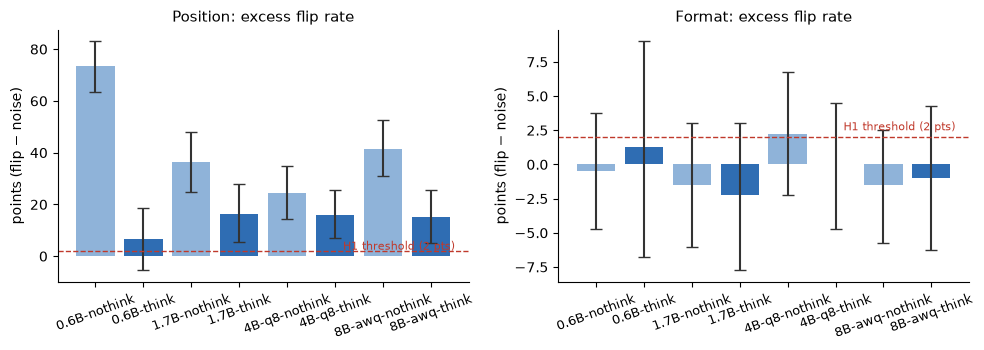

In [5]:
import matplotlib.pyplot as plt
ok = res.dropna(subset=["pos_excess"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, (m, lo, hi, title) in zip(axes, [("pos_excess", "pos_excess_lo", "pos_excess_hi", "Position: excess flip rate"),
                                         ("fmt_excess", "fmt_excess_lo", "fmt_excess_hi", "Format: excess flip rate")]):
    if m not in ok:
        continue
    y = ok[m] * 100
    ax.bar(range(len(ok)), y, color=["#8fb3d9" if "nothink" in c else "#2f6db3" for c in ok.index])
    ax.errorbar(range(len(ok)), y, yerr=[y - ok[lo] * 100, ok[hi] * 100 - y], fmt="none", ecolor="#333", capsize=4)
    ax.axhline(2, ls="--", lw=1, color="#c0392b"); ax.text(len(ok) - 0.5, 2.5, "H1 threshold (2 pts)", ha="right", fontsize=8, color="#c0392b")
    ax.set_xticks(range(len(ok))); ax.set_xticklabels(ok.index, rotation=20, fontsize=9)
    ax.set_title(title, fontsize=11); ax.set_ylabel("points (flip − noise)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(C.path("reports", "midterm_excess_flip.png"), dpi=150); plt.show()

In [6]:
C.log_version("06_midterm", "position+format bias on 100 pilot pairs, 0.6B/1.7B x think on/off",
              [C.path("reports", "midterm_results.csv")])
print("complete pairs per config:", {c: len(t) for c, t in tables.items()})

complete pairs per config: {'0.6B-nothink': 100, '0.6B-think': 100, '1.7B-nothink': 100, '1.7B-think': 100, '4B-q8-nothink': 100, '4B-q8-think': 100, '8B-awq-nothink': 100, '8B-awq-think': 100}
